# 10 · Rank a technician queue

When do learned rankings help a constrained operational decision?

Compare a fixed severity rule and a supervised ranker on historical-style synthetic episodes. Send each priority list through the same staffing solver. Replay identical arrivals and capacity and keep simulation outcomes separate from predictions.

**Measures** — Ranking quality, deadline misses, backlog and constraint violations.

**Evidence** — Evaluation table, staffing assumptions and a reproducible simulation replay.

**Runtime** — CPU. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 10

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if False and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "CPU",
  "python": "3.12.8",
  "platform": "Darwin",
  "packages": {
    "torch": "2.9.0",
    "transformers": "4.57.1",
    "numpy": "1.26.4",
    "scikit-learn": "1.7.2",
    "matplotlib": "3.10.9",
    "sentence-transformers": "5.1.2"
  },
  "smoke": false
}


# Lab 10 · Rank a technician queue

A facilities desk has three technicians and several tickets competing for the
next slot. The incumbent sorts by severity and deadline. We train a ranking
score from historical-style synthetic episodes and run both policies through
the same staffing solver. Ranking quality and dispatch outcomes have separate
ground truths. Every request, label, and staffing schedule is invented.

**Question.** Does a better ordering translate into fewer missed deadlines,
especially for high-impact tickets? A paired replay makes the staffing and
arrival assumptions inspectable. It supports conclusions about this
simulation only.

Run from the private course bundle in the configured notebook kernel. This
lab uses NumPy, scikit-learn and SciPy on CPU and calls no external services.
Integer times count 30-minute slots from the start of a synthetic shift.

In [6]:
from time import perf_counter

import numpy as np
from scipy.optimize import linear_sum_assignment
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import ndcg_score

SEED = 7010
FEATURES = ("severity", "slack", "duration", "sensor", "public_area")
TECHNICIANS = {
    "tech-1": frozenset({"HVAC", "electrical"}),
    "tech-2": frozenset({"plumbing", "electrical"}),
    "tech-3": frozenset({"HVAC", "plumbing"}),
}
RANKING_K = 10

Each ticket has an arrival slot, skill, severity, repair duration, and a
deadline. The simulated historical outcome is a graded impact label from 0
to 3. The learner sees intake features only. The simulator can later consult
the held-out labels to count high-impact misses, after both policies decide.

In [7]:
def make_episode(episode_id, rng):
    tickets = []
    for index in range(22):
        arrival = int(rng.integers(0, 9))
        duration = int(rng.integers(1, 5))
        slack = int(rng.integers(1, 7))
        severity = int(rng.integers(1, 5))
        sensor = float(rng.uniform())
        public_area = int(rng.integers(0, 2))
        impact = 0.60 * severity + 2.30 * sensor + 0.65 * public_area
        impact += float(rng.normal(0, 0.38))
        tickets.append({
            "ticket_id": f"queue-{episode_id:02d}-{index:02d}",
            "arrival": arrival,
            "deadline": arrival + duration + slack,
            "duration": duration,
            "skill": str(rng.choice(["HVAC", "plumbing", "electrical"])),
            "severity": severity,
            "slack": slack,
            "sensor": round(sensor, 3),
            "public_area": public_area,
            "impact_grade": int(np.digitize(impact, [1.8, 2.9, 4.0])),
        })
    return sorted(tickets, key=lambda ticket: (ticket["arrival"], ticket["ticket_id"]))


def feature_matrix(tickets):
    return np.array([[ticket[name] for name in FEATURES] for ticket in tickets])


rng = np.random.default_rng(SEED)
train_episodes = [make_episode(index, rng) for index in range(48)]
evaluation_episodes = [make_episode(index, rng) for index in range(48, 60)]
train_tickets = [ticket for episode in train_episodes for ticket in episode]
example_ticket = evaluation_episodes[0][0]
print("Ticket visible to dispatch:", {
    key: value for key, value in example_ticket.items() if key != "impact_grade"
})
print("Held-out impact grade used by the evaluator:", example_ticket["impact_grade"])

Ticket visible to dispatch: {'ticket_id': 'queue-48-13', 'arrival': 0, 'deadline': 10, 'duration': 4, 'skill': 'HVAC', 'severity': 2, 'slack': 6, 'sensor': 0.542, 'public_area': 1}
Held-out impact grade used by the evaluator: 2


The regressor learns an expected impact score. NDCG@10 checks whether high
graded-impact tickets move toward the front of each held-out episode.
Dispatch has current state that a static ranking does not have, including
which technicians are free. Both policies use the same earliest-deadline
and identifier tie-breakers. We fit once and tally each replay independently.

In [8]:
fit_start = perf_counter()
impact_model = HistGradientBoostingRegressor(
    max_iter=75, max_leaf_nodes=15, random_state=SEED,
)
impact_model.fit(
    feature_matrix(train_tickets),
    [ticket["impact_grade"] for ticket in train_tickets],
)
fit_ms = (perf_counter() - fit_start) * 1000


def incumbent_scores(tickets):
    return np.array([ticket["severity"] for ticket in tickets], dtype=float)


def learned_scores(tickets):
    return impact_model.predict(feature_matrix(tickets))


def policy_order(tickets, scores):
    return sorted(range(len(tickets)), key=lambda index: (
        -scores[index], tickets[index]["deadline"], tickets[index]["ticket_id"],
    ))


def staffing_matches(waiting, free_technicians, scores):
    if not free_technicians or not waiting:
        return []
    order = policy_order(waiting, scores)
    ranks = {index: len(waiting) - rank for rank, index in enumerate(order)}
    # Add idle columns so an available technician always has a feasible choice.
    # The cardinality bonus favors using more capacity before using queue rank.
    bonus = len(waiting) * len(free_technicians) + 1
    utility = np.zeros((len(free_technicians), len(waiting) + len(free_technicians)))
    utility[:, :len(waiting)] = -1
    for row, tech in enumerate(free_technicians):
        for column, ticket in enumerate(waiting):
            if ticket["skill"] in TECHNICIANS[tech]:
                utility[row, column] = bonus + ranks[column]
    rows, columns = linear_sum_assignment(utility, maximize=True)
    return [
        (free_technicians[row], waiting[column])
        for row, column in zip(rows, columns)
        if column < len(waiting) and utility[row, column] > 0
    ]


def replay(tickets, scores):
    score_by_id = {ticket["ticket_id"]: float(score) for ticket, score in zip(tickets, scores)}
    remaining = {ticket["ticket_id"]: ticket for ticket in tickets}
    busy_until = dict.fromkeys(TECHNICIANS, 0)
    dispatches = []
    peak_backlog = 0
    backlog_at_close = None
    closed = max(ticket["deadline"] for ticket in tickets)
    horizon = closed + sum(ticket["duration"] for ticket in tickets)
    for slot in range(horizon + 1):
        if not remaining and backlog_at_close is not None:
            break
        waiting = [ticket for ticket in remaining.values() if ticket["arrival"] <= slot]
        free_technicians = [tech for tech, available in busy_until.items() if available <= slot]
        assigned = staffing_matches(
            waiting,
            free_technicians,
            [score_by_id[ticket["ticket_id"]] for ticket in waiting],
        )
        for technician, ticket in assigned:
            finish = slot + ticket["duration"]
            dispatches.append({
                "ticket_id": ticket["ticket_id"],
                "technician": technician,
                "start": slot,
                "finish": finish,
                "missed_deadline": finish > ticket["deadline"],
                "high_impact": ticket["impact_grade"] == 3,
            })
            busy_until[technician] = finish
            remaining.pop(ticket["ticket_id"])
        backlog = len(waiting) - len(assigned)
        peak_backlog = max(peak_backlog, backlog)
        if slot == closed:
            backlog_at_close = backlog
    return dispatches, peak_backlog, backlog_at_close


def count_violations(tickets, dispatches):
    by_id = {ticket["ticket_id"]: ticket for ticket in tickets}
    seen = set()
    previous_finish = dict.fromkeys(TECHNICIANS, 0)
    violations = 0
    for dispatch in dispatches:
        ticket_id = dispatch["ticket_id"]
        ticket = by_id[ticket_id]
        technician = dispatch["technician"]
        overlaps = dispatch["start"] < previous_finish[technician]
        before_arrival = dispatch["start"] < ticket["arrival"]
        bad_skill = ticket["skill"] not in TECHNICIANS[technician]
        bad_duration = dispatch["finish"] - dispatch["start"] != ticket["duration"]
        violations += sum((ticket_id in seen, overlaps, before_arrival, bad_skill, bad_duration))
        seen.add(ticket_id)
        previous_finish[technician] = dispatch["finish"]
    return violations + len(set(by_id) - seen)

## Inspect one staffing decision

Assignment consumes a score, arrival time, repair duration, and skill
eligibility. A deliberately incompatible one-ticket example tests that the
solver can idle a technician even when the job ranks first.

In [9]:
episode = evaluation_episodes[0]
sample_scores = learned_scores(episode)
sample_dispatches, sample_backlog, _ = replay(episode, sample_scores)
assert count_violations(episode, sample_dispatches) == 0
assert staffing_matches([{"skill": "electrical", "deadline": 4, "ticket_id": "example"}],
                        ["tech-3"], [100]) == []
print("First dispatch:", sample_dispatches[0])
print("Peak waiting queue in this illustrative episode:", sample_backlog)

First dispatch: {'ticket_id': 'queue-48-13', 'technician': 'tech-1', 'start': 0, 'finish': 4, 'missed_deadline': False, 'high_impact': False}
Peak waiting queue in this illustrative episode: 12


## Compare both policies on the same episodes

The first run and warm repeats time the same prediction and solver workload.
We alternate policy order by episode. Setup and model fitting stay outside
the replay timings. Repeats capture local variation, not a service-level
latency estimate. Use the case records to locate cases where better
ordering helped, did nothing, or made the schedule worse.

{'policy': 'severity_rule', 'mean_ndcg_at_10': 0.871, 'deadline_misses': 109, 'high_impact_deadline_misses': 5, 'median_peak_backlog': 11.0, 'constraint_violations': 0}
{'policy': 'learned_impact', 'mean_ndcg_at_10': 0.974, 'deadline_misses': 104, 'high_impact_deadline_misses': 0, 'median_peak_backlog': 10.5, 'constraint_violations': 0}
Paired episode changes, learned minus rules: [{'episode': 48, 'ndcg_delta': 0.07488320497205192, 'miss_delta': 2, 'high_impact_miss_delta': 0}, {'episode': 49, 'ndcg_delta': 0.05988389044955422, 'miss_delta': 0, 'high_impact_miss_delta': 0}, {'episode': 50, 'ndcg_delta': 0.07049898421440559, 'miss_delta': -2, 'high_impact_miss_delta': 0}]
Fit time (ms): 488.583
Representative first/warm timings: [{'episode': 48, 'policy': 'severity_rule', 'phase': 'first_episode_pass', 'repeat': 0, 'wall_ms': 0.408}, {'episode': 48, 'policy': 'severity_rule', 'phase': 'warm_episode_repeat', 'repeat': 1, 'wall_ms': 0.135}, {'episode': 48, 'policy': 'severity_rule', 'phas

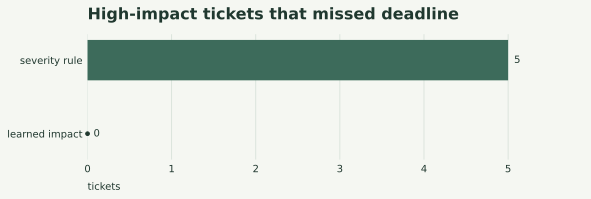

In [10]:
score_policies = {"severity_rule": incumbent_scores, "learned_impact": learned_scores}
case_rows = []
timing_rows = []
episode_rows = []
for index, tickets in enumerate(evaluation_episodes):
    grades = np.array([ticket["impact_grade"] for ticket in tickets])
    ordered_policies = list(score_policies) if index % 2 == 0 else list(reversed(score_policies))
    for policy in ordered_policies:
        for repeat in range(3):
            started = perf_counter()
            scores = score_policies[policy](tickets)
            dispatches, peak_backlog, close_backlog = replay(tickets, scores)
            elapsed_ms = (perf_counter() - started) * 1000
            timing_rows.append({
                "episode": index + 48,
                "policy": policy,
                "phase": "first_episode_pass" if repeat == 0 else "warm_episode_repeat",
                "repeat": repeat,
                "wall_ms": round(elapsed_ms, 3),
            })
            if repeat != 0:
                continue
            score_by_id = {ticket["ticket_id"]: float(score) for ticket, score in zip(tickets, scores)}
            ordinal_scores = np.empty(len(tickets))
            ordinal_scores[policy_order(tickets, scores)] = np.arange(len(tickets), 0, -1)
            episode_rows.append({
                "episode": index + 48,
                "policy": policy,
                "ndcg_at_10": float(ndcg_score([grades], [ordinal_scores], k=RANKING_K)),
                "misses": sum(row["missed_deadline"] for row in dispatches),
                "high_impact_misses": sum(
                    row["missed_deadline"] and row["high_impact"] for row in dispatches
                ),
                "peak_backlog": peak_backlog,
                "close_backlog": close_backlog,
                "constraint_violations": count_violations(tickets, dispatches),
            })
            case_rows.extend({
                **row,
                "episode": index + 48,
                "policy": policy,
                "priority_score": score_by_id[row["ticket_id"]],
            } for row in dispatches)

summaries = []
for policy in score_policies:
    entries = [row for row in episode_rows if row["policy"] == policy]
    summaries.append({
        "policy": policy,
        "mean_ndcg_at_10": round(float(np.mean([row["ndcg_at_10"] for row in entries])), 3),
        "deadline_misses": sum(row["misses"] for row in entries),
        "high_impact_deadline_misses": sum(row["high_impact_misses"] for row in entries),
        "median_peak_backlog": float(np.median([row["peak_backlog"] for row in entries])),
        "constraint_violations": sum(row["constraint_violations"] for row in entries),
    })
paired_episodes = []
for episode_id in range(48, 60):
    pair = {row["policy"]: row for row in episode_rows if row["episode"] == episode_id}
    paired_episodes.append({
        "episode": episode_id,
        "ndcg_delta": pair["learned_impact"]["ndcg_at_10"] - pair["severity_rule"]["ndcg_at_10"],
        "miss_delta": pair["learned_impact"]["misses"] - pair["severity_rule"]["misses"],
        "high_impact_miss_delta": (
            pair["learned_impact"]["high_impact_misses"] - pair["severity_rule"]["high_impact_misses"]
        ),
    })
assert len(case_rows) == 2 * sum(map(len, evaluation_episodes))
assert all(row["constraint_violations"] == 0 for row in summaries)
for summary in summaries:
    print(summary)
print("Paired episode changes, learned minus rules:", paired_episodes[:3])
print("Fit time (ms):", round(fit_ms, 3))
print("Representative first/warm timings:", timing_rows[:3])
save("summary", {
    "seed": SEED,
    "technician_skills": {name: sorted(skills) for name, skills in TECHNICIANS.items()},
    "training_episodes": len(train_episodes),
    "evaluation_episodes": len(evaluation_episodes),
    "fit_ms": fit_ms,
    "policies": summaries,
    "paired_episodes": paired_episodes,
})
save("records", {
    "dispatches": case_rows,
    "episodes": episode_rows,
    "timings": timing_rows,
    "input_episodes": evaluation_episodes,
})
chart(
    "High-impact tickets that missed deadline",
    [row["policy"] for row in summaries],
    [row["high_impact_deadline_misses"] for row in summaries],
    "tickets",
)

Interpret the two columns independently. NDCG rewards moving high-impact
tickets up. Deadline misses still depend on repair durations, absolute clock
time, and which skills are available. A policy can serve high-impact tickets
sooner yet increase other misses. A follow-on replay could change just
coverage in one trade and check whether that reverses the comparison.

[scikit-learn ranking metrics](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ndcg_score.html)
· [SciPy linear assignment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html)

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [XGBoost: A Scalable Tree Boosting System](https://arxiv.org/abs/1603.02754)
- [Google OR-Tools](https://developers.google.com/optimization)